<br>
<br>
<h2 style = "font-family: garamond; font-size: 50px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:10px;text-align:center; font-weight: bold" >Hey Siri!! is it a Cat or Dog?</h2> 
<br> 
<br>
<div class = 'image'> <img style="float:center; border:10px solid #fed049; width:90%" align=center src = https://metro.co.uk/wp-content/uploads/2015/11/mg_dogorcat_comp.png> 
</div>
<br>
<br>
<a href ="https://metro.co.uk/wp-content/uploads/2015/11/mg_dogorcat_comp.png" style = "font-size:20px,color: dimgrey, text-align:left,font-family:serif">Image Source: can we guess if youre a cat  or dog person</a>
<br>


<p style = "font-size: 20px; font-style: normal;color : #36609A;font-weight: bold" > Hope you find this notebook helpful and enjoy going through this notebook...Thanks and Happy Reading...</p>

<a id = '0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >Table of Contents</h2> 


*  [1. Introduction](#1.0)
*  [2. Initial Ground Work](#2.0)
*  [3. Data visualization](#3.0)
*  [4. Classification with Vanila CNN](#4.0)
   *  [4.1 Vanilla CNN이 이미지를 분류하는 과정 살펴보기](#4.1)
*  [5. Data agumentaion, learning rate schedule, and Early stoping](#5.0)
*  [6. Classification with ResNet](#6.0)
*  [7. Final predictions on Test Set](#7.0)
*  [8. Summary](#8.0)


<a id = '1.0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >1. Introduction</h2> 

<p style = "font-size: 20px; font-style: normal;color : #36609A;font-weight: bold" ><strong>Who doesn't love a cute cat and adorable dog? </strong></p>
These cute creatures are so addorable, and they reach all the way to computer vision compitions on kaggle. As humans we love our cute pets so much that, we can able to identify the speicis very easily, but can our computers able to do that without our help? 

Its kind of teach a machine to detect a thing in object. To teach which is cat? and which is dog? to computer we are going to build a deep learning model, which could be very basic to far complex based on our level of accuracy required and computational resources available. For this notebook, we are using a dogs and cats dataset, in which collection of images of dogs and cats and our objective is to build a basic CNN and classify dogs and cats from image, based on feature learning in hidden layers and activation maps in CNN. 

Whats the flow for this work? 
<ul><li> First, I will explore the dataset and attempt to make EDA of data</li>
    <li> later preprocess the data as requried, this includes image augumentations, scaling and what else need?</li>
    <li> Try to build a basic vanilla CNN, and try to predict species as a binary classification problem</li>
    <li> Later try to make predictions with transfer learning using ResNet50 and imagenet weights</li>
    <li> Finally compare the results on vanilla CNN and ResNet50 with sample data</li>
</ul>

<p style = "font-size: 30px; font-style: normal;color : #36609A;font-weight: bold" ><strong>Cute cute Dogs and cats </strong></p>


| | | |
|:-------------------------:|:-------------------------:|:-------------------------:|
|<img style="float:center; border:10px solid #fed049; width: 550px; height : 200px" src="https://i.insider.com/536aa78069bedddb13c60c3a?width=1000&format=jpeg&auto=webp">|<img style="float:center; border:10px solid #fed049; width: 550px; height : 200px" src="https://miro.medium.com/max/639/1*vg3kxX3H9eCNWKgBBeQHeA.jpeg">|<img style="float:center; border:10px solid #fed049; width: 550px; height : 200px" src="https://images.ctfassets.net/cnu0m8re1exe/7sLmeD1tcL4UoIm0BjNaLh/22a9f42a4315361db96470f50b178e86/Dog-and-Cat.jpg">|
|<img style = "float:center; border:10px solid #fed049; width: 550px; height : 200px" src="https://cdn.suwalls.com/wallpapers/animals/kitten-and-puppy-6928-1920x1200.jpg">|<img style = "float:center; border:10px solid #fed049; width: 550px; height : 200px" src="https://wallpaperaccess.com/full/1081184.jpg">|<img style = "float:center; border:10px solid #fed049; width: 550px; height : 200px" src="http://images4.fanpop.com/image/photos/16700000/Kittens-Puppies-teddybear64-16751426-1024-768.jpg">|
|<img style = "float:center; border:10px solid #fed049; width: 550px; height : 200px"  src="https://www.centrevillesquareanimalhospitalva.com/wp-content/uploads/2018/12/white_cat_and_dog.jpg">|<img style = "float:center; border:10px solid #fed049; width: 550px; height : 200px" src="https://s3.amazonaws.com/cdn-origin-etr.akc.org/wp-content/uploads/2017/09/12192216/Chihuahua-Kitten.jpg">|<img style = "float:center; border:10px solid #fed049; width: 550px; height : 200px" src="https://www.petbacker.com/blog/images/2017/dog-and-kitten.jpg">|

<br>
<a href ="https://www.google.com/search?q=dog+and+cat&rlz=1C1SQJL_enIN924IN924&sxsrf=ALeKk00fIZ8zlgT48DcdvzBb4Cvb5D4l1A:1621838427347&tbm=isch&source=iu&ictx=1&fir=BhriCENbREviAM%252CtgNZNGeRXuHXRM%252C_&vet=1&usg=AI4_-kQkz-AyFEDIX_UVuJZwrlUMfNCuMA&sa=X&ved=2ahUKEwjU3uD62uHwAhV35nMBHQ9YBRcQ9QF6BAgMEAE&biw=1536&bih=666#imgrc=lM_FAqlamnVj4M" style = "font-size:20px,color: dimgrey, text-align:left,font-family:serif">Images Source: Google.com</a>
<br>


<a id = '2.0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >2. Initial Ground Work</h2> 

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >loading all the required libraries.....</p>

### 실행 방법

Colab에서는 **모두 실행**을 누르세요. VS Code에서는 TensorFlow가 설치된 Python 3.12 커널을 선택한 뒤 **Run All**을 누르세요. 패키지가 필요하면 그 커널에서 `%pip install tensorflow pandas matplotlib seaborn scikit-learn scipy pillow`를 한 번 실행하세요.

Kaggle의 Dogs vs. Cats 데이터가 있으면 원본 학습 설정을 사용합니다. 로컬이나 Colab에 원본 데이터가 없으면 TensorFlow 튜토리얼의 공개 고양이·강아지 데이터로 짧은 실습을 실행합니다. 첫 실행에서는 이미지와 ResNet50의 사전학습 가중치를 다운로드합니다. 학습이 끝나면 **4.1**에서 특징 맵과 Grad-CAM을 확인할 수 있습니다.

In [3]:
import os
from pathlib import Path
from shutil import which
from zipfile import ZipFile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from tensorflow.keras import optimizers
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, Input, MaxPooling2D
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img, plot_model

%matplotlib inline

class color:
    BOLD = '\033[1m'
    BOLD_COLOR = '\033[1m\033[93m'
    END = '\033[0m'


SEED = 42
tf.keras.utils.set_random_seed(SEED)
print(f"TensorFlow {tf.__version__}")

ModuleNotFoundError: No module named 'tensorflow'


<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Color paleete for this notebook...</p>

In [ ]:
# color palette
colors = ['#EF7D71','#41ABD7','#36609A','#FFCE30','#194350']
sns.palplot(colors,size = 3)

plt.gcf().set_size_inches(15,5)

plt.text(-0.75,-0.75, 'Hey Siri! is it a Cat or Dog?: Color Palette',{'fontfamily':'serif', 'size':24, 'weight':'bold'})
plt.text(-0.75,-0.68, 'Lets try to stick to these colors throughout presentation.',{'fontfamily':'serif', 'size':16},alpha = 0.9)
for idx,values in enumerate(colors):
    plt.text(idx-0.25,0, colors[idx],{'fontfamily':'serif', 'size':16, 'weight':'bold','color':'#f5f6f6'}, alpha =1)
plt.gcf().set_facecolor('#f5f6f6')
plt.box(None)
plt.axis('off')
plt.text(3.5,0.65,'© Made by bhuvanchennoju/Kaggle',{'fontfamily':'serif', 'size':10,  'color':'black'})
plt.show()

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets Extract Labels from Image Names...</p>

In [ ]:
kaggle_dir = Path("/kaggle/input/dogs-vs-cats")
data_dir = Path("data")
train_dir, test_dir = data_dir / "train", data_dir / "test1"

# Reuse the Kaggle data if already extracted or mounted as competition archives.
for name, directory in [("train.zip", train_dir), ("test1.zip", test_dir)]:
    archive_path = kaggle_dir / name
    if not any(directory.glob("*.jpg")) and archive_path.is_file():
        with ZipFile(archive_path) as archive:
            archive.extractall(data_dir)

demo_run = not (any(train_dir.glob("cat.*.jpg"))
                and any(train_dir.glob("dog.*.jpg"))
                and any(test_dir.glob("*.jpg")))

if demo_run:
    # Public subset used by the TensorFlow transfer-learning tutorial.
    archive_path = Path(tf.keras.utils.get_file(
        fname="cats_and_dogs_filtered.zip",
        file_hash="91af24e0be191e9380dafc8710d0933fa826ec8e51f26f85c1fddba4e8018e3f",
        origin="https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip",
    ))
    dataset_dir = archive_path.parent / "cats_and_dogs_filtered"
    train_dir, test_dir = dataset_dir / "train", dataset_dir / "validation"
    extraction_complete = dataset_dir / ".extraction-complete"
    if not extraction_complete.is_file():
        with ZipFile(archive_path) as archive:
            archive.extractall(archive_path.parent)
        extraction_complete.touch()
    print("Dataset: TensorFlow cats and dogs tutorial (short demo)")
else:
    print("Dataset: Kaggle Dogs vs. Cats (full training)")

In [ ]:
train_files = sorted(train_dir.rglob("*.jpg"))
test_files = sorted(test_dir.rglob("*.jpg"))
print(f"Labeled training images: {len(train_files):,}")
print(f"Images for final predictions: {len(test_files):,}")

train_dir, test_dir = str(train_dir), str(test_dir)

In [ ]:
train_image_df = pd.DataFrame({
    "filename": [path.relative_to(Path(train_dir)).as_posix() for path in train_files],
    "category": [path.name.split(".")[0] for path in train_files],
})
submission_image_df = pd.DataFrame({
    "filename": [path.relative_to(Path(test_dir)).as_posix() for path in test_files],
})

<a id = '3.0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >3.Data visualization</h2> 

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets write helper funtions for path extraction and visualization of training images...</p>

In [ ]:
print(color.BOLD +'\n'+'Helper funtions for image path,id, category data extractions and Image visualizations' +'\n'+color.END)
def showImages(data,num_row  = 3,num_col =  3, name = 'any', subtitle = 'off'):
    """ This function creates a grid of images from  dataset.
    Shuffled images will be displayed.
    
    Input: 
    num_row: default: 3, no. of rows in a grid
    num_col: default:3, no. of columns in grid
    data: Dataframe of paths 
    name:  default 'any', takes: cat, dog, any or something else would give both
    subtitle: display id number for each image, defalult: 'off', takes: 'on' and 'off'
    Return: None
    
    """
    
    # little data sorting
    cat_df,dog_df = data[data['Category'] == 'cat'], data[data['Category'] == 'dog']

    
    if name == 'dog':
        X, Y  = dog_df['img_paths'], dog_df['ID_no']
    elif name == 'cat':
        X, Y  = cat_df['img_paths'], cat_df['ID_no']     
    else:
        X, Y  = data['img_paths'], data['ID_no']     # could use try and except but lets stick to minimal code

    (X_rand, Y_rand) = shuffle(X, Y)
    
    # showing images on matplotlib 
    
    fig, ax = plt.subplots(num_row,num_col,figsize = (12,12), dpi = 100)
    fig.patch.set_facecolor('#f5f6f6')
    axes = ax.ravel()
    
    for idx,ax  in enumerate(axes):
        x = load_img(X_rand.iloc[idx],target_size= (125, 125))
        ax.imshow(x)
        if subtitle == 'on':
            ax.set_title("{}".format(Y_rand.iloc[idx]))
        else:
            ax.set_title('')
        ax.axis('off')
        plt.subplots_adjust(wspace =0)
        del x
    #fig.tight_layout()
    
    fig.text(0.1,0.93, 'Hey Siri! is it a Cat or Dog?: {}s from Training Data'.format(name.capitalize()),{'fontfamily':'serif','size':18,'weight':'bold'})
    
    return None

In [ ]:
visual_df = pd.DataFrame({
    "ID_no": [path.stem.split(".")[-1] for path in train_files],
    "Category": train_image_df["category"],
    "img_paths": [str(path) for path in train_files],
})
display(visual_df.head())

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets see the images from training images...</p>

In [ ]:
showImages(visual_df,5,5, name = 'dog', subtitle = 'off')

In [ ]:
showImages(visual_df,5,5, name = 'cat', subtitle = 'off')

In [ ]:
showImages(visual_df,5,5, name = 'Dogs and Cat', subtitle = 'off')

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets split data into training and validation dataset, and visualize the data distribution...</p>

In [ ]:
train_valid_df, test_df = train_test_split(
    train_image_df, test_size=0.04, stratify=train_image_df["category"], random_state=SEED,
)
train_df, valid_df = train_test_split(
    train_valid_df, test_size=0.2, stratify=train_valid_df["category"], random_state=SEED,
)
if demo_run:
    # A balanced subset keeps both CNN training runs practical on a laptop CPU.
    train_df = train_df.groupby("category", group_keys=False).sample(n=192, random_state=SEED)
    valid_df = valid_df.groupby("category", group_keys=False).sample(n=48, random_state=SEED)
    submission_image_df = submission_image_df.sample(n=96, random_state=SEED)

print(f"Training: {len(train_df):,} | Validation: {len(valid_df):,} | Evaluation: {len(test_df):,}")
print(f"Images for final predictions: {len(submission_image_df):,}")

In [ ]:
fig = plt.figure(figsize =(8,8), dpi = 100)
fig.patch.set_facecolor('#f5f6f6')
gs = fig.add_gridspec(10,10)

ax0 = fig.add_subplot(gs[2:5,1:5])
ax1 = fig.add_subplot(gs[2:5,6:10])
ax2 = fig.add_subplot(gs[6:9,3:7])


axes = [ax0,ax1,ax2]
data  = [train_df['category'] ,  valid_df['category'], test_df['category']]
labels = ['Training Data','Validation Data','Testing Data']

for ax in axes:
    ax.set_facecolor('#f5f6f6')
    ax.axes.get_yaxis().set_visible(False)
    
    for loc in ['left','right','top','bottom']:
        ax.spines[loc].set_visible(False)
    
for ax,df, label in zip(axes,data,labels):
    sns.countplot(x=df, hue=df, ax=ax, palette=[colors[2], colors[3]], legend=False)
    ax.set_xlabel(xlabel = ' ')
    for pa in ax.patches: 
        ax.text(pa.get_x(), pa.get_height(),'{}'.format(pa.get_height()), **{'fontfamily':'serif', 'size':10, 'weight':'bold'}, alpha = 1)

    ax.text(0,0,label,**{'fontfamily':'serif', 'size':10, 'weight':'bold'})

fig.text(0.1,0.82, 'Hey Siri!! is it a Cat or Dog?: Images Distribution',{'fontfamily':'serif','size':18,'weight':'bold'})
fig.text(0.1,0.77, '''All the image distributions are fairly balanced so, hope we can
get fair accuracy as well''',{'fontfamily':'serif','size':12,})

fig.text(0.75,0.15,'© Made by bhuvanchennoju/Kaggle',{'fontfamily':'serif', 'size':10,  'color':'black'})
fig.show()

<a id = '4.0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >4. Classification with Vanilla CNN</h2> 

First, train the Vanilla CNN on the cat and dog images. Section 6 uses a pretrained ResNet50 for comparison.

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" > Let prepared training, validation, testing data for vanilla CNN without any agumentations...</p>

In [ ]:
img_size = 96 if demo_run else 224
batch_size = 32 if demo_run else 128

print(color.BOLD_COLOR + '\nPreparing train and validation images for training...' + color.END)
# dataframe iterators without data agumnetation

vani_preprocessing = ImageDataGenerator(rescale=1 / 255 if demo_run else None)

print(color.BOLD)
        
#Creatinga a dataframe iterators for fitting
vani_train_data = vani_preprocessing.flow_from_dataframe(
            train_df,train_dir,
            x_col = 'filename',
            y_col = 'category',
            target_size = (img_size, img_size),
            batch_size = batch_size,
            class_mode = 'categorical')

vani_valid_data = vani_preprocessing.flow_from_dataframe(
             valid_df, train_dir,
             x_col = 'filename',
             y_col = 'category',
             target_size = (img_size, img_size),
             batch_size = batch_size,
             class_mode = 'categorical')


vani_test_data = vani_preprocessing.flow_from_dataframe(
             test_df, train_dir,
             x_col = 'filename',
             y_col = None,
             target_size = (img_size, img_size),
             batch_size = batch_size,
             class_mode = None,
             shuffle = False)

print(color.BOLD_COLOR + '\nDone!')

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets build vanila CNN model ...</p>

In [ ]:
#Building model computational graph
vani_model = Sequential()
vani_model.add(Input(shape=(img_size, img_size, 3)))
vani_model.add(Conv2D(16, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(Conv2D(16, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(MaxPooling2D(pool_size = (2,2), strides=(2,2)))

vani_model.add(Conv2D(32, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(Conv2D(32, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(MaxPooling2D(pool_size = (2,2), strides=(2,2)))

vani_model.add(Conv2D(64, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(Conv2D(64, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(MaxPooling2D(pool_size = (2,2),strides=(2,2)))

vani_model.add(Conv2D(128, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(Conv2D(128, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(MaxPooling2D(pool_size = (2,2),strides=(2,2)))

vani_model.add(Dropout(0.3))

vani_model.add(Conv2D(256, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(Conv2D(256, (3,3), activation = 'relu', padding = 'same'))
vani_model.add(MaxPooling2D(pool_size = (2,2),strides=(2,2)))

vani_model.add(Dropout(0.3))

vani_model.add(Flatten())

vani_model.add(Dense(512, activation = 'relu'))

vani_model.add(Dropout(0.5))

vani_model.add(Dense(2, activation = 'softmax'))

print(color.BOLD_COLOR + '\nVanilla Model layers and output shapes with params...\n'+color.END)

print(color.BOLD)
vani_model.summary()

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets See vanila CNN model Schematic diagram ...</p>

In [ ]:
if which("dot"):
    try:
        display(plot_model(vani_model, show_shapes=True, expand_nested=True, dpi=80))
    except ImportError:
        vani_model.summary()
else:
    vani_model.summary()

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets train and validate on vanila CNN model ...</p>

In [ ]:
vani_model.compile(
    loss="categorical_crossentropy",
    optimizer=optimizers.Adam(learning_rate=3e-4 if demo_run else 1e-4),
    metrics=["accuracy"],
)
vani_history = vani_model.fit(
    vani_train_data,
    epochs=3 if demo_run else 15,
    validation_data=vani_valid_data,
    verbose=2,
)

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets plot vanila CNN model change in loss and accuracys with epochs ...</p>

In [ ]:
fig,ax  = plt.subplots(2,1, figsize =(8,8), dpi = 100)
fig.patch.set_facecolor('#f5f6f6')

axes  = ax.ravel()

for ax in axes:
    ax.set_facecolor('#f5f6f6')
    for loc in ['right','top',]:
        ax.spines[loc].set_visible(False)
        
hist1 = vani_history.history
Epochs =  range(len(hist1['loss']))

## loss plot
sns.lineplot(x = Epochs, y = hist1['val_loss'],  ax = axes[0], linewidth = 4, color = colors[3])
sns.lineplot(x = Epochs, y = hist1['loss'], ax  = axes[0], linewidth =4,  color = colors[4])


axes[0].text(Epochs[-1]+0.25,hist1['val_loss'][-1],'Validation Loss',{'fontfamily':'serif', 'size':12, 'weight':'bold','color':colors[3]})
axes[0].text(Epochs[-1]+0.25,hist1['loss'][-1] ,'Training Loss',{'fontfamily':'serif', 'size':12, 'weight':'bold','color':colors[4]})


# accuracy plot
sns.lineplot(x = Epochs, y = hist1['val_accuracy'],ax = axes[1],linewidth = 4, color = colors[3])
sns.lineplot(x = Epochs, y = hist1['accuracy'],ax = axes[1],linewidth =4,  color = colors[4])
axes[1].text(Epochs[-1]+0.25,hist1['val_accuracy'][-1],'Validation Accuracy',{'fontfamily':'serif', 'size':12, 'weight':'bold','color':colors[3]})
axes[1].text(Epochs[-1]+0.25,hist1['accuracy'][-1] ,'Training Accuracy',{'fontfamily':'serif', 'size':12, 'weight':'bold','color':colors[4]})


fig.text(0,1.06, 'Hey Siri! is it a Cat or Dog?: Vanilla Loss and Accuracy ',{'fontfamily':'serif', 'size':18, 'weight':'bold'})
fig.text(0,1.01, '''Compare the training and validation curves for this run.''',{'fontfamily':'serif', 'size':12})
        
fig.text(0.75,-0.05,'© Made by bhuvanchennoju/Kaggle',{'fontfamily':'serif', 'size':10,  'color':'black'})
plt.tight_layout(h_pad = 5)

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets see vanila CNN predictions with confusion matrix ...</p>

In [ ]:
vani_pred = vani_model.predict(vani_test_data)
test_df['vani_pred'] = np.argmax(vani_pred, axis = -1)
labels = dict((v,k) for k,v in vani_train_data.class_indices.items())

test_df['vani_pred'] = test_df['vani_pred'].map(labels)

In [ ]:
def make_confusion_matrix(cf,
                          group_names=None,
                          categories='auto',
                          count=True,
                          percent=True,
                          cbar=True,
                          xyticks=True,
                          xyplotlabels=True,
                          sum_stats=True,
                          figsize=None,
                          cmap='Blues',
                          title=None):


    # CODE TO GENERATE TEXT INSIDE EACH SQUARE
    blanks = ['' for i in range(cf.size)]

    if group_names and len(group_names)==cf.size:
        group_labels = ["{}\n".format(value) for value in group_names]
    else:
        group_labels = blanks

    if count:
        group_counts = ["{0:0.0f}\n".format(value) for value in cf.flatten()]
    else:
        group_counts = blanks

    if percent:
        group_percentages = ["{0:.2%}".format(value) for value in cf.flatten()/np.sum(cf)]
    else:
        group_percentages = blanks

    box_labels = [f"{v1}{v2}{v3}".strip() for v1, v2, v3 in zip(group_labels,group_counts,group_percentages)]
    box_labels = np.asarray(box_labels).reshape(cf.shape[0],cf.shape[1])


    # CODE TO GENERATE SUMMARY STATISTICS & TEXT FOR SUMMARY STATS
    if sum_stats:
        #Accuracy is sum of diagonal divided by total observations
        accuracy  = np.trace(cf) / float(np.sum(cf))

        #if it is a binary confusion matrix, show some more stats
        if len(cf)==2:
            #Metrics for Binary Confusion Matrices
            true_positives = cf[1, 1]
            predicted_positives = cf[:, 1].sum()
            actual_positives = cf[1, :].sum()
            precision = true_positives / max(1, predicted_positives)
            recall = true_positives / max(1, actual_positives)
            f1_score = 2 * true_positives / max(1, predicted_positives + actual_positives)
            stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
                accuracy,precision,recall,f1_score)
        else:
            stats_text = "\n\nAccuracy={:0.3f}".format(accuracy)
    else:
        stats_text = ""


    # SET FIGURE PARAMETERS ACCORDING TO OTHER ARGUMENTS
    if figsize==None:
        #Get default figure size if not set
        figsize = plt.rcParams.get('figure.figsize')

    if xyticks==False:
        #Do not show categories if xyticks is False
        categories=False


    # MAKE THE HEATMAP VISUALIZATION
    fig = plt.figure(figsize=figsize)
    fig.patch.set_facecolor('#f5f6f6')
    sns.heatmap(cf,annot=box_labels,fmt="",linewidths = 1,square = True,linecolor= '#f5f6f6',
                cmap=cmap,cbar=cbar,annot_kws={'fontfamily':'serif','size':18,'weight':'bold'},
                xticklabels=categories,
                yticklabels=categories,)

    if xyplotlabels:
        plt.ylabel('True label', **{'fontfamily':'serif','size':12,'weight':'bold'})
        plt.xlabel('Predicted label' + stats_text,**{'fontfamily':'serif','size':12,'weight':'bold'})
    else:
        plt.xlabel(stats_text,**{'fontfamily':'serif','size':12,'weight':'bold'})
    
    ax = plt.gca()
    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set(fontfamily="serif", fontsize=16, fontweight="bold")

In [ ]:
vani_cf_matrix = confusion_matrix(test_df['category'], test_df['vani_pred'], labels=['cat', 'dog'])
my_cols = [colors[3],colors[2]]

labels = [ 'True Neg','False Pos','False Neg','True Pos']
categories = ['Cat', 'Dog']
make_confusion_matrix(vani_cf_matrix,figsize = (10,5),
                      group_names=labels,cbar = False,cmap = matplotlib.colors.LinearSegmentedColormap.from_list("",my_cols),
                      categories=categories, 
                      title = 'Vanila CNN comfusion matrix')

plt.gcf().text(0,1.1,'Hey Siri! is it a Cat or Dog?: Vanilla CNN Test Data Evaluation',{'fontfamily':'serif', 'size':24,  'color':'black', 'weight':'bold'})
plt.gcf().text(0,0.995,"""Evaluate the Vanilla CNN on images held out of training.""",{'fontfamily':'serif', 'size':14,  'color':'black', })

plt.gcf().text(0.85,-0.15,'© Made by bhuvanchennoju/Kaggle',{'fontfamily':'serif', 'size':10,  'color':'black'})
plt.gcf().show()

<a id="4.1"></a>

### 4.1 Vanilla CNN이 이미지를 분류하는 과정 살펴보기

앞에서 학습한 Vanilla CNN에 고양이 또는 강아지 사진 한 장을 넣어 봅시다. 아래 셀의 `example_index`를 바꾸면 평가용 데이터에서 다른 사진을 볼 수 있습니다.

**특징 맵(Feature map)**은 CNN 레이어의 채널이 이미지의 어느 위치에 얼마나 강하게 반응했는지 보여줍니다. 각 행에서는 평균 반응이 큰 채널 4개를 그립니다. 밝은 부분은 그 지도 안에서 반응이 큰 위치입니다.

- **첫 번째 합성곱(First convolution)**에서 밝은 부분이 사진의 윤곽이나 털의 질감과 어디에서 겹치는지 찾으세요.
- **첫 번째 풀링(First max pooling)**은 작은 영역마다 가장 큰 값을 남깁니다. 첫 행과 비교해 출력의 가로·세로 크기가 얼마나 줄었는지 확인하세요.
- **마지막 합성곱(Last convolution)**은 앞 레이어의 특징을 조합합니다. 마지막 행에서 어느 위치에 반응이 모여 있는지 살펴보세요.

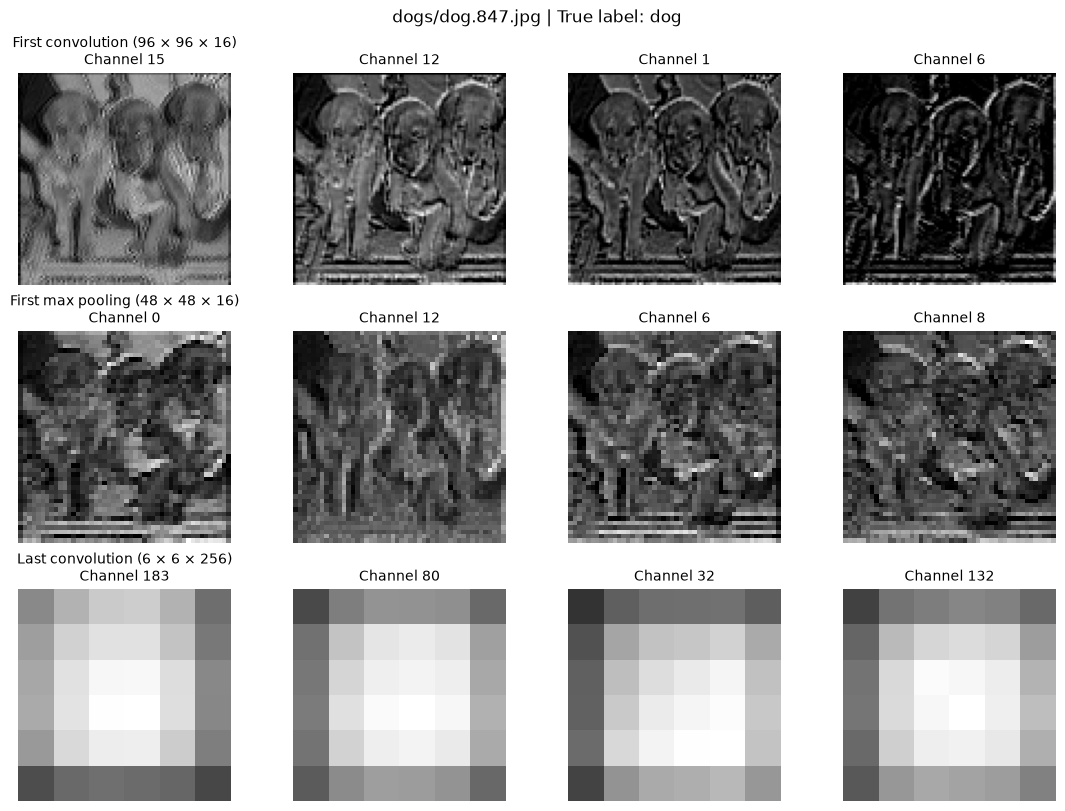

In [ ]:
# 평가용 이미지 한 장을 골라 Vanilla CNN과 같은 방식으로 준비합니다.
example_index = 0
example = test_df.iloc[example_index]
example_image = load_img(
    os.path.join(train_dir, example["filename"]),
    target_size=(img_size, img_size),
)
example_array = vani_test_data.image_data_generator.standardize(img_to_array(example_image))
image_batch = tf.convert_to_tensor(example_array[None, ...])  # (1, 높이, 너비, RGB)

# 학습된 모델에서 관찰할 레이어의 중간 출력만 꺼냅니다.
conv_layers = [layer for layer in vani_model.layers if isinstance(layer, Conv2D)]
first_pool = next(layer for layer in vani_model.layers if isinstance(layer, MaxPooling2D))
feature_layers = [
    ("First convolution", conv_layers[0]),
    ("First max pooling", first_pool),
    ("Last convolution", conv_layers[-1]),
]
feature_model = Model(
    inputs=vani_model.inputs[0],
    outputs=[layer.output for _, layer in feature_layers],
)
feature_outputs = feature_model(image_batch, training=False)

fig, axes = plt.subplots(3, 4, figsize=(11, 8), constrained_layout=True)
fig.suptitle(f"{example['filename']} | True label: {example['category']}")

for row, ((layer_title, _), feature_output) in enumerate(zip(feature_layers, feature_outputs)):
    maps = feature_output[0].numpy()  # (높이, 너비, 채널)
    height, width, channels = maps.shape
    selected_channels = np.argsort(maps.mean(axis=(0, 1)))[-4:][::-1]

    for col, channel in enumerate(selected_channels):
        ax = axes[row, col]
        channel_map = maps[:, :, channel]
        ax.imshow(channel_map, cmap="gray", vmin=0, vmax=max(float(channel_map.max()), 1e-8))
        title = f"Channel {channel}"
        if col == 0:
            title = f"{layer_title} ({height} × {width} × {channels})\n{title}"
        ax.set_title(title, fontsize=10)
        ax.axis("off")

plt.show()

#### 예측에 영향을 준 영역 보기 (Grad-CAM)

같은 사진에 대해 CNN이 예측한 클래스의 점수를 기준으로 **Grad-CAM**을 그립니다. 마지막 합성곱의 각 채널이 그 점수에 미치는 영향을 기울기로 계산합니다. 그 영향을 가중치로 써서 채널별 특징 맵을 한 장의 지도로 합칩니다.

오른쪽 그림에서 밝은 영역이 얼굴, 몸통, 배경 중 어디에 겹치는지 찾아보세요. 이 지도는 마지막 합성곱 출력을 확대해 만든 것이므로 대략적인 위치를 보여줍니다. 위 셀에서 사진을 바꿔 모델이 사진마다 어떤 영역에 반응하는지 비교해 보세요.

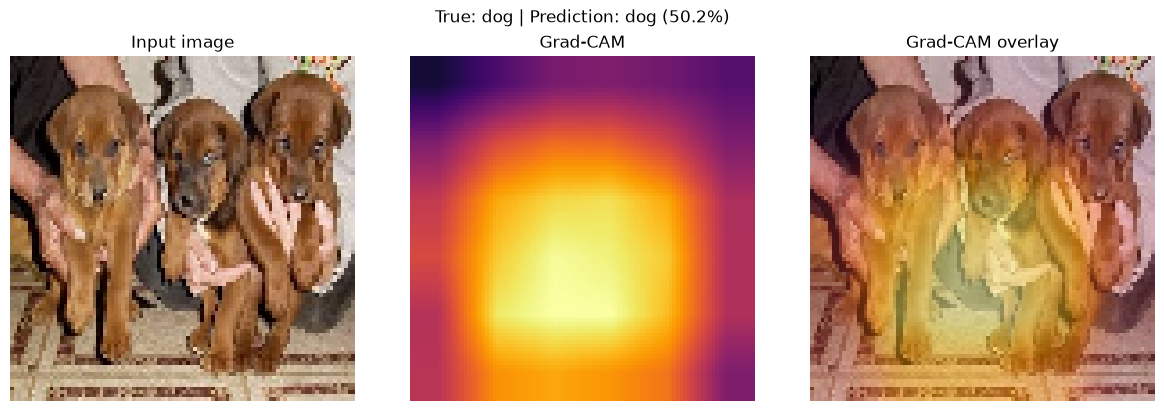

In [ ]:
# 위 셀에서 얻은 마지막 합성곱 출력을 분류층까지 전달합니다.
last_maps = feature_outputs[-1]
last_conv_index = vani_model.layers.index(conv_layers[-1])
classifier = vani_model.layers[-1]

with tf.GradientTape() as tape:
    tape.watch(last_maps)
    classifier_input = last_maps
    for layer in vani_model.layers[last_conv_index + 1:-1]:
        classifier_input = layer(classifier_input, training=False)

    # 마지막 Dense 층의 softmax 적용 전 클래스 점수를 계산합니다.
    class_scores = tf.matmul(classifier_input, classifier.kernel) + classifier.bias
    predicted_class = int(tf.argmax(class_scores[0]).numpy())
    class_score = class_scores[0, predicted_class]

# 위치별 기울기를 채널마다 평균 내고 특징 맵에 가중치로 적용합니다.
gradients = tape.gradient(class_score, last_maps)
channel_weights = tf.reduce_mean(gradients[0], axis=(0, 1))
heatmap = tf.nn.relu(tf.reduce_sum(last_maps[0] * channel_weights, axis=-1))
heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))
heatmap = tf.image.resize(heatmap[..., None], (img_size, img_size))[:, :, 0].numpy()

class_names = {index: name for name, index in vani_train_data.class_indices.items()}
predicted_name = class_names[predicted_class]
probabilities = tf.nn.softmax(class_scores, axis=-1)
predicted_probability = float(probabilities[0, predicted_class].numpy())

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
fig.suptitle(f"True: {example['category']} | Prediction: {predicted_name} ({predicted_probability:.1%})")
axes[0].imshow(example_image)
axes[0].set_title("Input image")
axes[1].imshow(heatmap, cmap="inferno", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM")
axes[2].imshow(example_image)
axes[2].imshow(heatmap, cmap="inferno", vmin=0, vmax=1, alpha=0.55 * heatmap)
axes[2].set_title("Grad-CAM overlay")
for ax in axes:
    ax.axis("off")

plt.show()


<a id = '5.0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >5. Data Agumentation, Early Stopping, Learning Rate Schedule</h2> 

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" > Lets code helper function for visualization of image agumentation...</p>

In [ ]:
print(color.BOLD +'\n'+'Helper funtions for Image Agumentation visualizations' +'\n'+color.END)

def data_argumentation_show(n, grid_size):
    sample_aug_map = ImageDataGenerator(
            #zoom_range = 0.1,
            rotation_range = 25,
            horizontal_flip = True,
            height_shift_range =0.2,
            width_shift_range = 0.2,
            fill_mode='nearest',
            rescale = 1/255)
    sample_data = sample_aug_map.flow_from_dataframe(
            (train_df.sample(n)),
            train_dir,
            x_col = 'filename',
            y_col = 'category',
            target_size = (img_size, img_size),
            class_mode = 'categorical')
  
  #subplot grid 
    fig = plt.figure(figsize = (10,10))
    fig.patch.set_facecolor('#f5f6f6')
    for i in range(0,grid_size*grid_size):
        plt.subplot(grid_size,grid_size, i+1)
        for x,y in sample_data:
            img = x[0]
            plt.imshow(img)
            plt.axis('off')
            break
            plt.tight_layout()
            del img
    fig.show()

     
    fig.text(0.1,0.93, 'Hey Siri! is it cat or dog?: Image agumentation',{'fontfamily':'serif','size':20,'weight':'bold'})
    
    return None



In [ ]:
# To visulalize the effect of data argumentation 
#select number of samples to argument----> n = 
# total number of argumentation is grid_Size**2

data_argumentation_show(1, 5)

In [ ]:
data_argumentation_show(2, 5)

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" > Decaying learing rate setting function...</p>

In [ ]:
print(color.BOLD + '\nSetting a decay learning rate for learning rate schedule\n'+ color.END)
epoch = 50
learning_rate = 3e-5 
lr_start = 0.00000001
lr_min = 0.000001
lr_max = 3e-5 
lr_rampup_epochs = 1
lr_sustain_epochs = 1
lr_exp_decay = .8

def lrfn(epoch):
    if epoch < lr_rampup_epochs:
        lr = (lr_max - lr_start) / lr_rampup_epochs * epoch + lr_start
    elif epoch < lr_rampup_epochs + lr_sustain_epochs:
        lr = lr_max
    else:
        lr = (lr_max - lr_min) * lr_exp_decay**(epoch - lr_rampup_epochs - lr_sustain_epochs) + lr_min
    return lr
    
print(color.BOLD_COLOR + 'Done!' +color.END)


In [ ]:
epochs = 20
epochs_range = [i for i in range(50 if epochs<50 else epochs)]
learn_rate = [lrfn(x) for x in epochs_range]


fig,ax = plt.subplots(figsize = (10,5))
fig.patch.set_facecolor('#f5f6f6')
ax.set_facecolor('#f5f6f6')

for loc in ['right','top',]:
    ax.spines[loc].set_visible(False)

ax.plot(epochs_range, learn_rate, linewidth = 4, color= colors[2]) 
plt.xlabel('Range of epochs',{'fontfamily':'serif', 'size':14,  'color':'black', 'weight':'bold'})
plt.ylabel('Learning rate in 10^-5',{'fontfamily':'serif', 'size':14,  'color':'black', 'weight':'bold'})


plt.gcf().text(0,1.06,'Hey Siri! is it a cat or dog?: Learning Rate Schedule',{'fontfamily':'serif', 'size':24,  'color':'black', 'weight':'bold'})
plt.gcf().text(0,0.975,"""Initially set a learning rate that linearly increase from 1e-08 to 3e-5 and later
exponentially decreases from 3e-5 to 1e-6""",{'fontfamily':'serif', 'size':14,  'color':'black', })

plt.gcf().text(0.75,0,'© Made by bhuvanchennoju/Kaggle',{'fontfamily':'serif', 'size':10,  'color':'black'})
plt.gcf().show()

<a id = '6.0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >6. Classification with ResNet50</h2> 

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" > Image agumentation data preparation with ImageDataGenerator</p>

In [ ]:
print(color.BOLD_COLOR + '\n Agumenting Train, Validation images... and testing images just passing through... \n'+ color.END)

print(color.BOLD)
# using standard data augumentation

train_aug_map = ImageDataGenerator(
                    rotation_range=10,
                    #zoom_range=0.1,
                    horizontal_flip=True,
                    fill_mode='nearest',
                    #width_shift_range=0.1,
                    #height_shift_range=0.1,
                    preprocessing_function = preprocess_input)
res_train_data = train_aug_map.flow_from_dataframe(
            train_df, train_dir,
            x_col = 'filename',
            y_col = 'category',
            target_size = (img_size, img_size),
            batch_size = batch_size,
            class_mode = 'categorical')

#one should validate the generality of model on the actcual target images
#so not supposed agumentation
valid_aug_map = ImageDataGenerator(preprocessing_function = preprocess_input)

res_valid_data = valid_aug_map.flow_from_dataframe(
             valid_df, train_dir,
             x_col = 'filename',
             y_col = 'category',
             target_size = (img_size, img_size),
             batch_size = batch_size,
             class_mode = 'categorical')


#test data rescaling images

test_aug_map = ImageDataGenerator(preprocessing_function = preprocess_input)

res_test_data = test_aug_map.flow_from_dataframe(
             test_df, train_dir,
             x_col = 'filename',
             y_col = None,
             class_mode = None,
             target_size = (img_size, img_size),
             shuffle = False)
           


<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" > Building model for transfer learning on top of pretrained ResNet50 Model...</p>

In [ ]:
#loading resent 
resNet = tf.keras.applications.ResNet50(weights = 'imagenet',
                        include_top = False,
                        input_shape = (img_size, img_size, 3))

resNet.trainable = False # Freeze layers
resNet_model = Sequential([
        resNet,
        Flatten(),
        Dense(1024, activation = 'relu'),
        Dropout(0.4),
        Dense(2, activation = 'softmax')])
     

optimizer = optimizers.Adam(1e-5)

print(color.BOLD_COLOR + '\nResNet based Transfer learning Model layers and output shapes with params...\n'+color.END)

print(color.BOLD)
resNet_model.summary()
#plot_model(resNet_model, to_file='resNet_model.png')

In [ ]:
print(color.BOLD + '\nSetting early stopping factor and learning rate schedule\n' +color.END)

earlystop = EarlyStopping(patience= 5)
    
lr_callback = LearningRateScheduler(lrfn, verbose = True)

callbacks = [earlystop, lr_callback]
print(color.BOLD_COLOR + 'Done!')

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets train and validate Pre-trained ResNet50 model for top layers...</p>

In [ ]:
resNet_model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])
resnet_history = resNet_model.fit(
    res_train_data,
    epochs=2 if demo_run else 15,
    validation_data=res_valid_data,
    callbacks=callbacks,
    verbose=2,
)

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets plot Resnet models change in loss and accuracys with epochs ...</p>

In [ ]:
fig,ax  = plt.subplots(2,1, figsize =(8,8), dpi = 100)
fig.patch.set_facecolor('#f5f6f6')

axes  = ax.ravel()

for ax in axes:
    ax.set_facecolor('#f5f6f6')
    for loc in ['right','top',]:
        ax.spines[loc].set_visible(False)
        
hist2 = resnet_history.history
Epochs =  range(len(hist2['loss']))

## loss plot
sns.lineplot(x = Epochs, y = hist2['val_loss'],  ax = axes[0], linewidth = 4, color = colors[3])
sns.lineplot(x = Epochs, y = hist2['loss'], ax  = axes[0], linewidth =4,  color = colors[4])


axes[0].text(Epochs[-1]+0.25,hist2['val_loss'][-1],'Validation Loss',{'fontfamily':'serif', 'size':12, 'weight':'bold','color':colors[3]})
axes[0].text(Epochs[-1]+0.25,hist2['loss'][-1]-0.1 ,'Training Loss',{'fontfamily':'serif', 'size':12, 'weight':'bold','color':colors[4]})


# accuracy plot
sns.lineplot(x = Epochs, y = hist2['val_accuracy'],ax = axes[1],linewidth = 4, color = colors[3])
sns.lineplot(x = Epochs, y = hist2['accuracy'],ax = axes[1],linewidth =4,  color = colors[4])
axes[1].text(Epochs[-1]+0.25,hist2['val_accuracy'][-1]-0.04,'Validation Accuracy',{'fontfamily':'serif', 'size':12, 'weight':'bold','color':colors[3]})
axes[1].text(Epochs[-1]+0.25,hist2['accuracy'][-1] ,'Training Accuracy',{'fontfamily':'serif', 'size':12, 'weight':'bold','color':colors[4]})


fig.text(0,1.06, 'Hey Siri! is it a cat or dog?: ResNet Loss and Accuracy ',{'fontfamily':'serif', 'size':18, 'weight':'bold'})
fig.text(0,1.01, '''Compare the training and validation curves of the transfer-learning model.''',{'fontfamily':'serif', 'size':12})
fig.text(0.75,-0.05,'© Made by bhuvanchennoju/Kaggle',{'fontfamily':'serif', 'size':10,  'color':'black'})
        
plt.tight_layout(h_pad = 5)

fig.show()

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets see ResNet predictions with confusion matrix ...</p>

In [ ]:
res_pred = resNet_model.predict(res_test_data)
test_df['res_pred'] = np.argmax(res_pred, axis = -1)
labels = dict((v,k) for k,v in res_train_data.class_indices.items())

test_df['res_pred'] = test_df['res_pred'].map(labels)

In [ ]:
res_cf_matrix = confusion_matrix(test_df['category'], test_df['res_pred'], labels=['cat', 'dog'])
my_cols = [colors[3],colors[2]]

labels = [ 'True Neg','False Pos','False Neg','True Pos']
categories = ['Cat', 'Dog']
make_confusion_matrix(res_cf_matrix,figsize = (10,5),
                      group_names=labels,cbar = False,cmap = matplotlib.colors.LinearSegmentedColormap.from_list("",my_cols),
                      categories=categories, 
                      title = 'Vanila CNN comfusion matrix')

plt.gcf().text(0,1.1,'Hey Siri! is it a cat or dog?: ResNet Test Data Evaluation',{'fontfamily':'serif', 'size':24,  'color':'black', 'weight':'bold'})
plt.gcf().text(0,0.995,"""The metrics below are computed from the predictions in this run.""",{'fontfamily':'serif', 'size':14,  'color':'black', })

plt.gcf().text(0.85,-0.15,'© Made by bhuvanchennoju/Kaggle',{'fontfamily':'serif', 'size':10,  'color':'black'})
plt.gcf().show()

<a id = '7.0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >7. Final predictions on Test Set</h2> 

In [ ]:
print(color.BOLD_COLOR + '\n Final test data preperation for both vanilla and resnet for final predictions \n'+ color.END)
# generating an dataframe iterator for test dataset

print(color.BOLD)
res_sub_aug_map = ImageDataGenerator(preprocessing_function = preprocess_input)

vani_sub_data = vani_preprocessing.flow_from_dataframe(
             submission_image_df, test_dir,
             x_col = 'filename',
             y_col = None,
             class_mode = None,
             target_size = (img_size, img_size),
             shuffle = False)


res_sub_data = res_sub_aug_map.flow_from_dataframe(
             submission_image_df, test_dir,
             x_col = 'filename',
             y_col = None,
             class_mode = None,
             target_size = (img_size, img_size),
             shuffle = False)

In [ ]:
print(color.BOLD_COLOR + '\n Making final predictions with both resnet and vanilla cnns for Test data'+color.END)
vani_pred_sub = vani_model.predict(vani_sub_data)
submission_image_df['vani_pred_sub'] = np.argmax(vani_pred_sub, axis = -1)
labels = {index: name for name, index in vani_train_data.class_indices.items()}
submission_image_df['vani_pred_sub'] = submission_image_df['vani_pred_sub'].map(labels)


res_pred_sub = resNet_model.predict(res_sub_data)
submission_image_df['res_pred_sub'] = np.argmax(res_pred_sub, axis = -1)
labels = {index: name for name, index in res_train_data.class_indices.items()}
submission_image_df['res_pred_sub'] = submission_image_df['res_pred_sub'].map(labels)

print(color.BOLD)
print(submission_image_df.head())

<p style = "font-size: 25px; font-style: normal;color : #36609A;font-weight:bold" >Lets see how our predictions are done on Test Data by both networks...</p>

In [ ]:
pred_sample = submission_image_df.sample(18)
pred_sample.reset_index(drop = True, inplace = True)

fig = plt.figure(figsize=(12,24))
fig.patch.set_facecolor('#f5f6f6')

for index, row in pred_sample.iterrows():
    filename = row['filename']
    vani_pred = row['vani_pred_sub']
    res_pred = row['res_pred_sub']
    img = load_img(os.path.join(test_dir, filename), target_size= (img_size, img_size))
    plt.subplot(6,3, index+1)
    plt.imshow(img)
    plt.gca().axis('off')
    ax = plt.gca()
    ax.text(0.97, 0.19, f"Vanilla: {vani_pred}", transform=ax.transAxes, ha="right",
            color="lightgreen", fontsize=11, bbox=dict(facecolor="black", alpha=0.9))
    ax.text(0.97, 0.06, f"ResNet: {res_pred}", transform=ax.transAxes, ha="right",
            color="white", fontsize=11, bbox=dict(facecolor="black", alpha=0.9))
    #plt.title(filename.split('.')[0])
    del img
plt.tight_layout()
#plt.subplots_adjust( wspace=0, hspace= 1)
fig.text(0,1, 'Hey Siri! is it cat or dog?: Test data labels',{'fontfamily':'serif','size':24,'weight':'bold'})
fig.show()

<a id = '8.0'></a>
<h2 style = "font-family: garamond; font-size: 40px; font-style: normal; letter-spcaing: 3px; background-color:#FFCE30 ; color : #36609A; border-radius: 5px 5px; padding:3px;text-align:center; font-weight: bold" >8. Summary</h2> 

<p style = "font-size: 30px; font-style: normal;color : #36609A;font-weight:bold" >What happened so far?</p>

So far, I have tried to build a cat and dog classifier with help of deeplearning models, lets see the steps 
<ol>
    <li>Data processing and visualization</li>
    <li>Build a basic CNN and make prections</li>
    <li>Explored Data Agumentation and Learning rate Schedule</li>
    <li>Build a Resnet based Transfer leraning model and make prections</li>
    <li>final comparision of both models results</li>
</ol>

<p style = "font-size: 30px; font-style: normal;color : #36609A;font-weight:bold" >Thank you so much for reading all the way here.....Hope you enjoyed my work.....!!! I am open to suggetions. Please do comment if you any advice or critical comments... Thanks again!!!</p>